# Spotify Track Dataset - EDA

Objective: inspect the Spotify track dataset, understand data quality, explore important audio features, and prepare feature candidates for recommendation and prediction models.

## 1. Setup

Import libraries and configure display options.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

## 2. Load Dataset

In [2]:
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "data").exists())
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "dataset.csv"

df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
df.head()

Rows: 114,000
Columns: 21


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 3. Basic Structure

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,NaN,NaN,NaN,56999.5,32909.109681,0.0,28499.75,56999.5,85499.25,113999.0
track_id,114000,89741,6S3JlDAGk3uu3NtZbPnuhS,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artists,113999,31437,The Beatles,279,NaN,NaN,NaN,NaN,NaN,NaN,NaN
album_name,113999,46589,Alternative Christmas 2022,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_name,113999,73608,Run Rudolph Run,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,114000.0,NaN,NaN,NaN,33.238535,22.305078,0.0,17.0,35.0,50.0,100.0
duration_ms,114000.0,NaN,NaN,NaN,228029.153114,107297.712645,0.0,174066.0,212906.0,261506.0,5237295.0
explicit,114000,2,False,104253,NaN,NaN,NaN,NaN,NaN,NaN,NaN
danceability,114000.0,NaN,NaN,NaN,0.5668,0.173542,0.0,0.456,0.58,0.695,0.985
energy,114000.0,NaN,NaN,NaN,0.641383,0.251529,0.0,0.472,0.685,0.854,1.0


## 4. Missing Values And Duplicates

In [5]:
missing = df.isna().sum().sort_values(ascending=False)
missing[missing > 0]

artists       1
track_name    1
album_name    1
dtype: int64

In [6]:
duplicate_track_ids = df["track_id"].duplicated().sum()
print(f"Duplicate track_id rows: {duplicate_track_ids:,}")

df[df.duplicated("track_id", keep=False)].sort_values("track_id").head(20)

Duplicate track_id rows: 24,259


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
15028,15028,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,1,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,chill
103211,103211,001APMDOl3qtx1526T11n1,Pink Sweat$;Kirby,New RnB,Better,0,176320,False,0.613,0.471,1,-6.644,0,0.1070,0.31600,0.000001,0.1170,0.406,143.064,4,soul
85578,85578,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,2,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,punk-rock
100420,100420,001YQlnDSduXd5LgBd66gT,Soda Stereo,Soda Stereo (Remastered),El Tiempo Es Dinero - Remasterizado 2007,38,177266,False,0.554,0.921,2,-4.589,1,0.0758,0.01940,0.088100,0.3290,0.700,183.571,1,ska
91801,91801,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,rock
3257,3257,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alternative
2106,2106,003vvx7Niy0yvhvHt4a68B,The Killers,Hot Fuss,Mr. Brightside,86,222973,False,0.352,0.911,1,-5.230,1,0.0747,0.00121,0.000000,0.0995,0.236,148.033,4,alt-rock
33178,33178,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,5,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,emo
94239,94239,004h8smbIoAkUNDJvVKwkG,Ouse;Powfu,Loners Diary,Lovemark,58,219482,True,0.808,0.331,5,-13.457,1,0.0557,0.13100,0.000000,0.2250,0.337,140.035,4,sad
97533,97533,006rHBBNLJMpQs8fRC2GDe,Calcinha Preta;Gusttavo Lima,CP 25 Anos (Ao Vivo em Aracaju),Agora Estou Sofrendo - Ao Vivo,47,260510,False,0.605,0.678,0,-3.257,1,0.0311,0.64200,0.000000,0.1570,0.439,125.059,4,sertanejo


## 5. Initial Cleaning For EDA

This creates an EDA-safe copy. The raw dataframe stays unchanged.

In [7]:
eda = df.copy()
eda = eda.drop(columns=["Unnamed: 0"], errors="ignore")
eda = eda.dropna(subset=["track_name", "artists"])
eda["album_name"] = eda["album_name"].fillna("Unknown")
eda["duration_min"] = eda["duration_ms"] / 60000
eda["explicit_int"] = eda["explicit"].astype(int)

text_cols = ["artists", "album_name", "track_name", "track_genre"]
for col in text_cols:
    eda[col] = eda[col].astype(str).str.strip()

print(eda.shape)
eda.head()

(113999, 22)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_min,explicit_int
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,3.844433,0
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,2.493500,0
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,3.513767,0
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,3.365550,0
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,3.314217,0


## 6. Validate Numeric Ranges

In [8]:
range_checks = {
    "popularity_outside_0_100": eda[(eda["popularity"] < 0) | (eda["popularity"] > 100)].shape[0],
    "duration_ms_lte_0": eda[eda["duration_ms"] <= 0].shape[0],
    "tempo_lte_0": eda[eda["tempo"] <= 0].shape[0],
}
range_checks

{'popularity_outside_0_100': 0, 'duration_ms_lte_0': 0, 'tempo_lte_0': 157}

In [9]:
audio_cols = [
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "duration_min"
]

eda[audio_cols + ["popularity"]].describe().T

,count,mean,std,min,25%,50%,75%,max
danceability,113999.0,0.566801,0.173543,0.0000,0.4560,0.580000,0.695000,0.98500
energy,113999.0,0.641383,0.251530,0.0000,0.4720,0.685000,0.854000,1.00000
loudness,113999.0,-8.258950,5.029357,-49.5310,-10.0130,-7.004000,-5.003000,4.53200
speechiness,113999.0,0.084652,0.105733,0.0000,0.0359,0.048900,0.084500,0.96500
acousticness,113999.0,0.314907,0.332522,0.0000,0.0169,0.169000,0.597500,0.99600
instrumentalness,113999.0,0.156051,0.309556,0.0000,0.0000,0.000042,0.049000,1.00000
liveness,113999.0,0.213554,0.190378,0.0000,0.0980,0.132000,0.273000,1.00000
valence,113999.0,0.474066,0.259261,0.0000,0.2600,0.464000,0.683000,0.99500
tempo,113999.0,122.147695,29.978290,0.0000,99.2185,122.017000,140.071000,243.37200
duration_min,113999.0,3.800519,1.788268,0.1431,2.9011,3.548433,4.358433,87.28825


## 7. Genre And Popularity Overview

In [10]:
print(f"Number of genres: {eda['track_genre'].nunique()}")
eda["track_genre"].value_counts().head(20)

Number of genres: 114


track_genre
acoustic         1000
afrobeat         1000
alt-rock         1000
alternative      1000
ambient          1000
anime            1000
black-metal      1000
bluegrass        1000
blues            1000
brazil           1000
breakbeat        1000
british          1000
cantopop         1000
chicago-house    1000
children         1000
chill            1000
classical        1000
club             1000
comedy           1000
country          1000
Name: count, dtype: int64

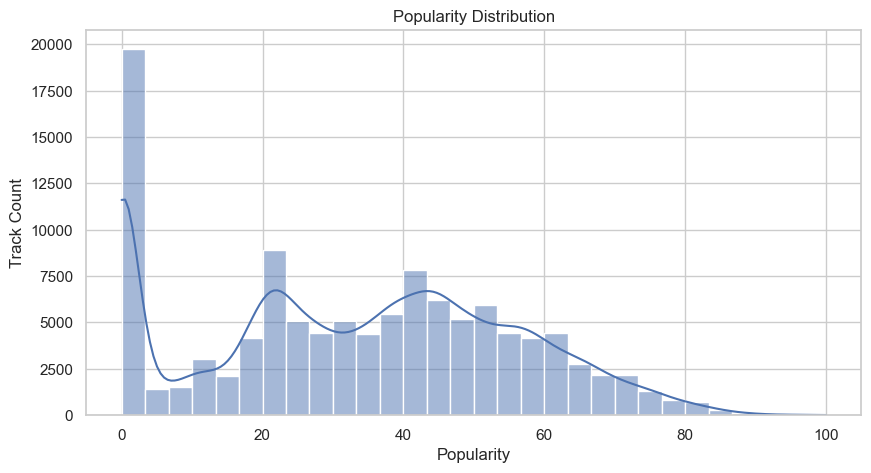

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(eda["popularity"], bins=30, kde=True)
plt.title("Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Track Count")
plt.show()

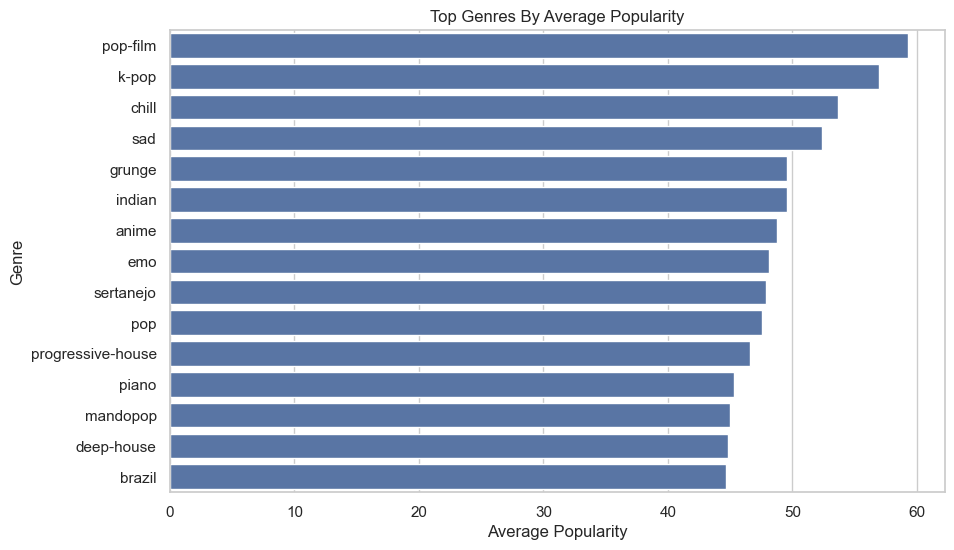

In [12]:
top_genres = eda.groupby("track_genre")["popularity"].mean().sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title("Top Genres By Average Popularity")
plt.xlabel("Average Popularity")
plt.ylabel("Genre")
plt.show()

## 8. Audio Feature Distributions

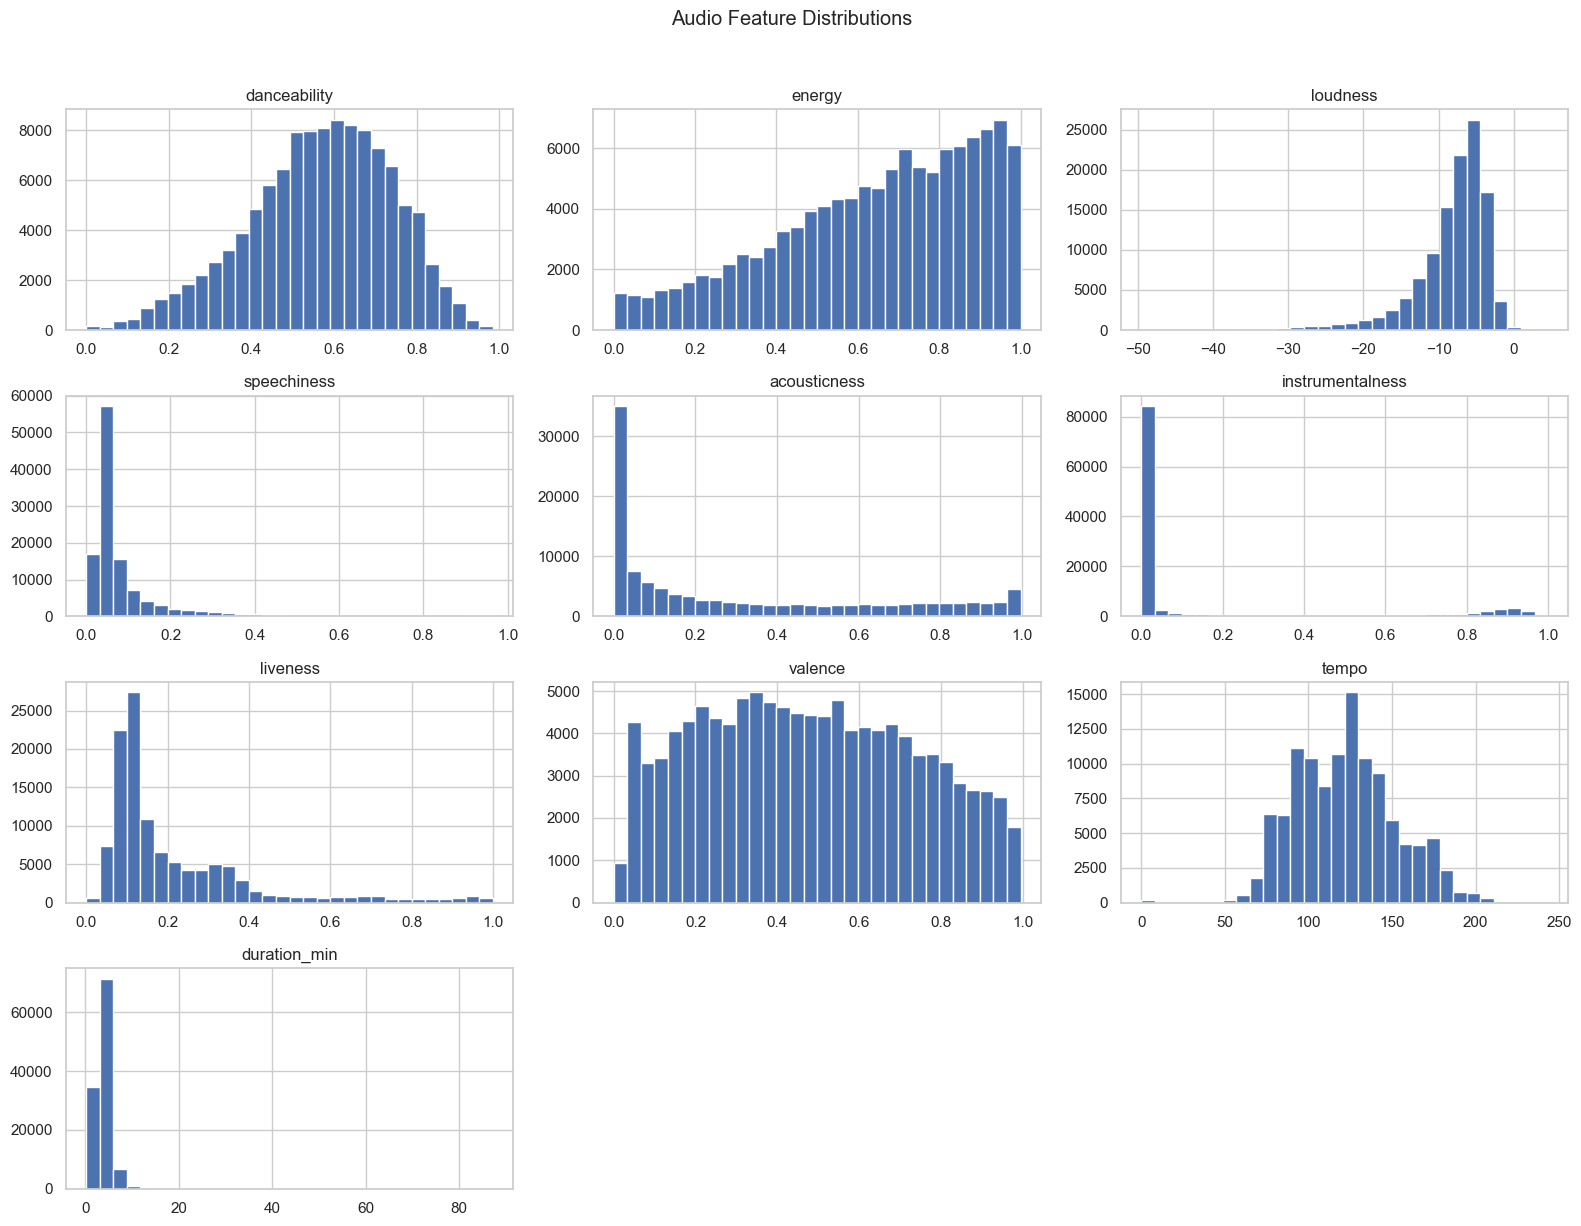

In [13]:
eda[audio_cols].hist(figsize=(16, 12), bins=30)
plt.suptitle("Audio Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

## 9. Correlation Analysis

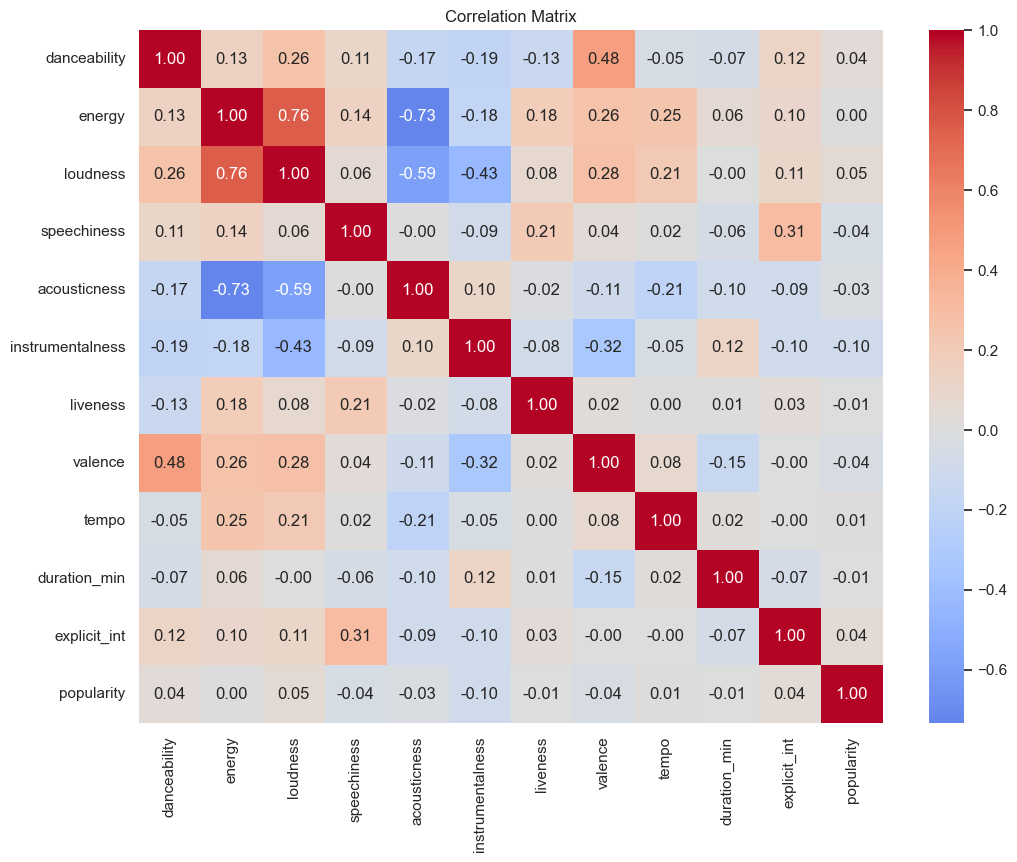

In [14]:
corr_cols = audio_cols + ["explicit_int", "popularity"]
corr = eda[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

In [15]:
corr["popularity"].drop("popularity").sort_values(key=lambda s: s.abs(), ascending=False)

instrumentalness   -0.095147
loudness            0.050420
speechiness        -0.044930
explicit_int        0.044078
valence            -0.040522
danceability        0.035444
acousticness       -0.025458
tempo               0.013212
duration_min       -0.007129
liveness           -0.005397
energy              0.001053
Name: popularity, dtype: float64

## 10. Feature Relationships

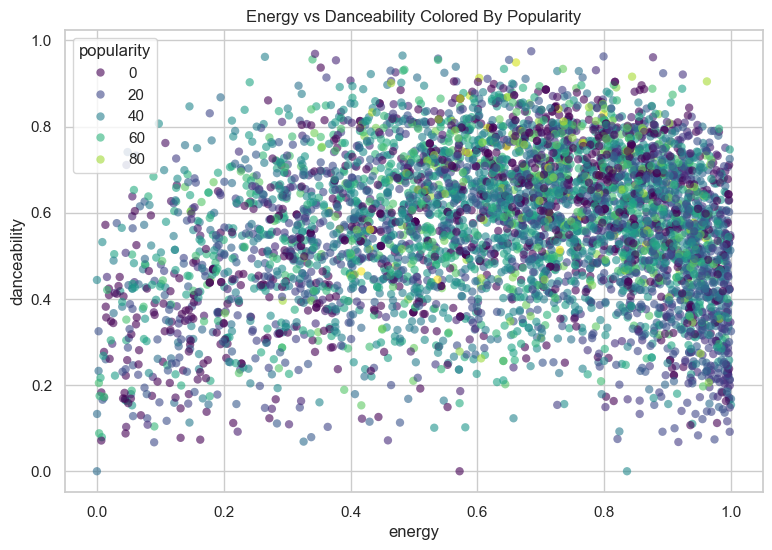

In [16]:
sample = eda.sample(min(5000, len(eda)), random_state=42)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=sample, x="energy", y="danceability", hue="popularity", palette="viridis", alpha=0.6, linewidth=0)
plt.title("Energy vs Danceability Colored By Popularity")
plt.show()

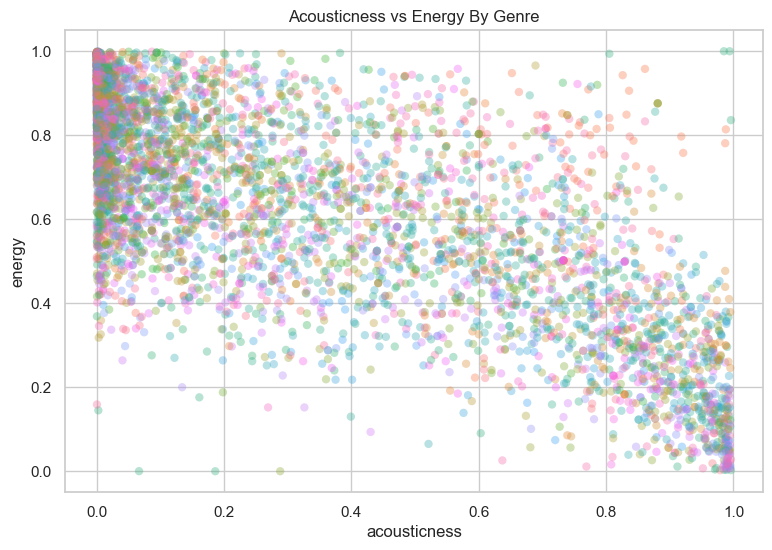

In [17]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=sample, x="acousticness", y="energy", hue="track_genre", legend=False, alpha=0.35, linewidth=0)
plt.title("Acousticness vs Energy By Genre")
plt.show()

## 11. Candidate Features For Recommendation

In [18]:
candidate_features = [
    "track_genre", "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence",
    "tempo", "duration_min", "explicit_int", "popularity"
]

eda[candidate_features].head()

,track_genre,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_min,explicit_int,popularity
0,acoustic,0.676,0.4610,-6.746,0.1430,0.0322,0.000001,0.3580,0.715,87.917,3.844433,0,73
1,acoustic,0.420,0.1660,-17.235,0.0763,0.9240,0.000006,0.1010,0.267,77.489,2.493500,0,55
2,acoustic,0.438,0.3590,-9.734,0.0557,0.2100,0.000000,0.1170,0.120,76.332,3.513767,0,57
3,acoustic,0.266,0.0596,-18.515,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3.365550,0,71
4,acoustic,0.618,0.4430,-9.681,0.0526,0.4690,0.000000,0.0829,0.167,119.949,3.314217,0,82


## 12. Save Cleaned EDA Dataset

In [19]:
OUTPUT_PATH = PROJECT_ROOT / "data" / "processed" / "spotify_cleaned_eda.csv"
eda.to_csv(OUTPUT_PATH, index=False)
print(f"Saved cleaned EDA dataset to: {OUTPUT_PATH}")

Saved cleaned EDA dataset to: ../data/processed/spotify_cleaned_eda.csv


## Notes For Next Step

After running this notebook, use the EDA findings to choose dashboard inputs and modeling features. For the recommender, start with scaled audio features and genre filtering. For popularity prediction, compare baseline regression models and evaluate whether audio features alone are strong enough.